[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zjelveh/zjelveh.github.io/blob/master/files/ccjs418e_fall2026/8b_plotting_with_dates.ipynb)

**Save your own copy.**
1. Click File > Save a copy in Drive.
2. Rename it.
3. Work in your copy.

---

# 8b. Plotting with Dates: Before and After a Cutoff
## CCJS 418E: Coding for Criminology — Fall 2026

In Problem Set 2, we compared DC crime reports from the 30 days before August 11, 2025 with the 30 days starting that date, using counts and daily averages. Today we will put the same reports on a timeline.

Our questions are:

- How do we turn text dates into values Seaborn can place on a timeline?
- How do we mark the August 11 cutoff on a chart?
- Which time unit, days or weeks, shows the before/after comparison more clearly?

Two cells begin with `# Expected ...Error`. They fail on purpose. Read each error, then run the next cell.

In [1]:
# Show the result of every line in a cell, so one cell can display several outputs
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

# pandas works with tables of data
import pandas as pd
# NumPy handles the numbers stored inside pandas tables
import numpy as np
# Seaborn draws the charts
import seaborn as sns
# Matplotlib adds lines, labels, and titles to Seaborn charts
import matplotlib.pyplot as plt

# Print NumPy numbers as plain values, such as 3 instead of np.int64(3)
np.set_printoptions(legacy="1.25")
# Draw charts on a white background with light grid lines
sns.set_style('whitegrid')
# Make every chart 9 inches wide and 4 inches tall
plt.rcParams['figure.figsize'] = (9, 4)

## Setup: DC Crime Reports

This is the Problem Set 2 file. **One row represents one crime report.**

| Column | Meaning |
|---|---|
| `record_id` | Report identifier |
| `report_date` | Date the report was recorded |
| `offense` | Offense category |
| `ward` | DC ward (0 means unknown) |
| `period` | `Before` for July 12–August 10, `After` for August 11–September 9 |
| `is_violent` | `True` for violent offense categories |

The Problem Set 2 file also has a `days_from_cutoff` column. We will build that column ourselves in Part 4, so we keep the six columns above.

In [2]:
data_url = 'https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2026/dc_crime_ps2.csv'
df = pd.read_csv(filepath_or_buffer=data_url)
df = df[['record_id', 'report_date', 'offense', 'ward', 'period', 'is_violent']]

df.head(n=5)
df.shape

,record_id,report_date,offense,ward,period,is_violent
0,25101173,2025-07-12,MOTOR VEHICLE THEFT,6,Before,False
1,25104322,2025-07-12,MOTOR VEHICLE THEFT,7,Before,False
2,25104442,2025-07-12,THEFT F/AUTO,7,Before,False
3,25104460,2025-07-12,THEFT F/AUTO,4,Before,False
4,25104661,2025-07-12,THEFT F/AUTO,3,Before,False


(4406, 6)

## Part 1: What the Dates Look Like

The `report_date` values look like dates. Check how pandas stored them: the column's data type, its first values, and the type of a single value.

In [3]:
df['report_date'].dtype
df['report_date'].head(n=3)
type(df['report_date'].iloc[0])

dtype('O')

0    2025-07-12
1    2025-07-12
2    2025-07-12
Name: report_date, dtype: object

str

`object` and `str` tell us that pandas stored each date as **text**, the same way it stores offense names.

Count the reports on each date. Then plot those counts with the text dates on the horizontal axis.

,report_date,n_reports
0,2025-07-12,55
1,2025-07-13,48
2,2025-07-14,69
3,2025-07-15,74
4,2025-07-16,70


<Axes: xlabel='report_date', ylabel='n_reports'>

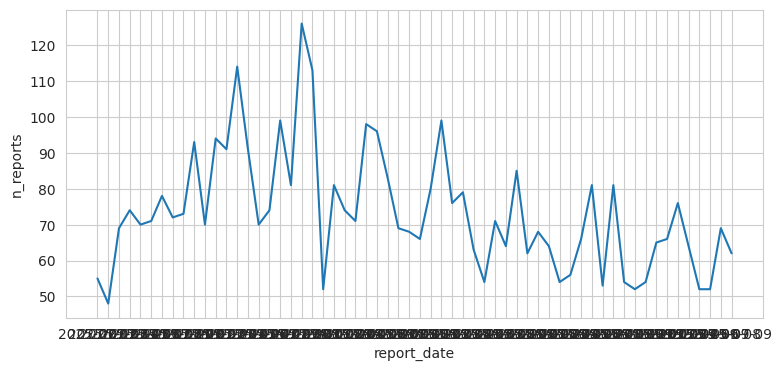

In [4]:
daily_text = df.groupby(by=['report_date']).size().reset_index(name='n_reports')
daily_text.head(n=5)

sns.lineplot(data=daily_text, x='report_date', y='n_reports')

### Read the Horizontal Axis

Seaborn treats each text value as a category name, the way it treats borough names on a bar chart. It places the 60 dates at evenly spaced positions and prints all 60 labels, so they run together. A timeline needs values that pandas recognizes as dates.

## Part 2: Convert the Column with `pd.to_datetime()`

`pd.to_datetime()` reads each text value and stores it as a date. We replace the text column with the converted one.

In [5]:
df['report_date'] = pd.to_datetime(arg=df['report_date'])

df['report_date'].dtype
df['report_date'].head(n=3)
df['report_date'].dt.day_name().head(n=3)

dtype('<M8[ns]')

0   2025-07-12
1   2025-07-12
2   2025-07-12
Name: report_date, dtype: datetime64[ns]

0    Saturday
1    Saturday
2    Saturday
Name: report_date, dtype: object

The dates print the same way, and the data type is now `datetime64[ns]`: each value is a point in time. `.dt.day_name()` works on the converted column, as it did in the datetime notebook.

Rebuild the daily table from the converted column and plot it.

,report_date,n_reports
0,2025-07-12,55
1,2025-07-13,48
2,2025-07-14,69
3,2025-07-15,74
4,2025-07-16,70


<Axes: xlabel='report_date', ylabel='n_reports'>

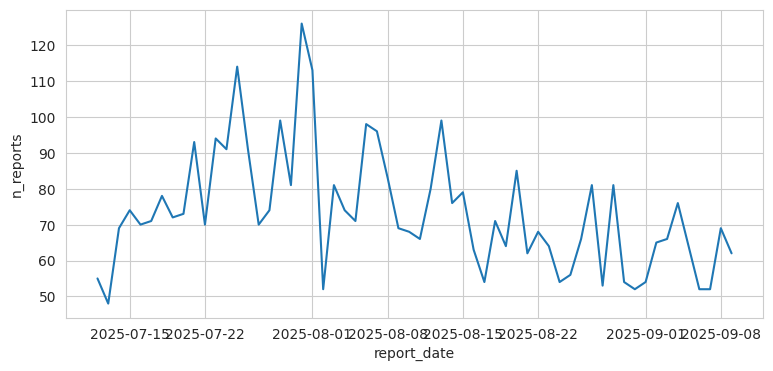

In [6]:
daily = df.groupby(by=['report_date']).size().reset_index(name='n_reports')
daily.head(n=5)

sns.lineplot(data=daily, x='report_date', y='n_reports')

### Compare the Two Charts

Both charts plot the same 60 daily counts. Each point is the number of reports recorded on one date. The second chart has a timeline on its horizontal axis: Seaborn spaces the dates by calendar time and labels a few of them.

## Part 3: Mark the Cutoff with a Vertical Line

`plt.axvline()` draws a vertical line across the chart. Its `x=` value is the line's position on the horizontal axis, so it uses the same kind of value as the axis. Our axis holds dates, so we give the line a date.

| Argument | Meaning |
|---|---|
| `x=cutoff` | Position on the horizontal axis: August 11, 2025 |
| `color='red'` | Line color |
| `linestyle='--'` | Dashed line |

`plt.tick_params(axis='x', labelrotation=45)` tilts the date labels to give them room.

<Axes: xlabel='report_date', ylabel='n_reports'>

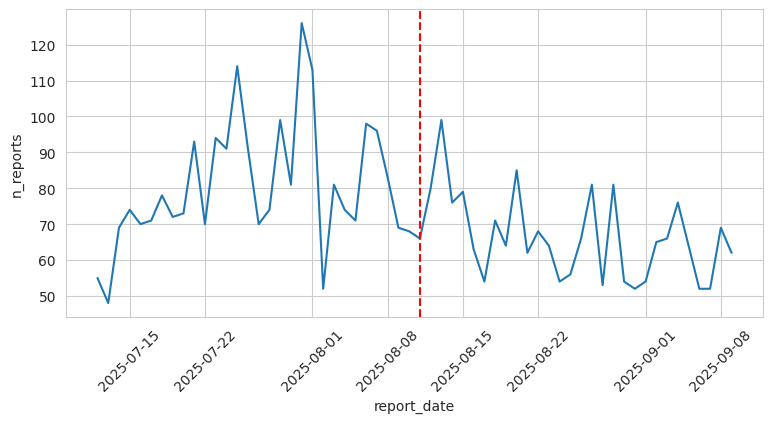

In [7]:
cutoff = pd.to_datetime(arg='2025-08-11')

sns.lineplot(data=daily, x='report_date', y='n_reports')
plt.axvline(x=cutoff, color='red', linestyle='--')
plt.tick_params(axis='x', labelrotation=45)

Run the next cell and read its error. This time the line's position is the text `'2025-08-11'`.

In [ ]:
# Expected ConversionError: place the line at a text date
sns.lineplot(data=daily, x='report_date', y='n_reports')
plt.axvline(x='2025-08-11', color='red', linestyle='--')

The error says that Matplotlib, the library underneath Seaborn, failed to convert the text to the axis's units. Converting the position with `pd.to_datetime()` gives it those units, as in the cell before it.

### Color the Two Periods

`hue='period'` draws the Before and After reports as separate lines with a legend. The table needs a `period` column, so we group by date and period.

<Axes: xlabel='report_date', ylabel='n_reports'>

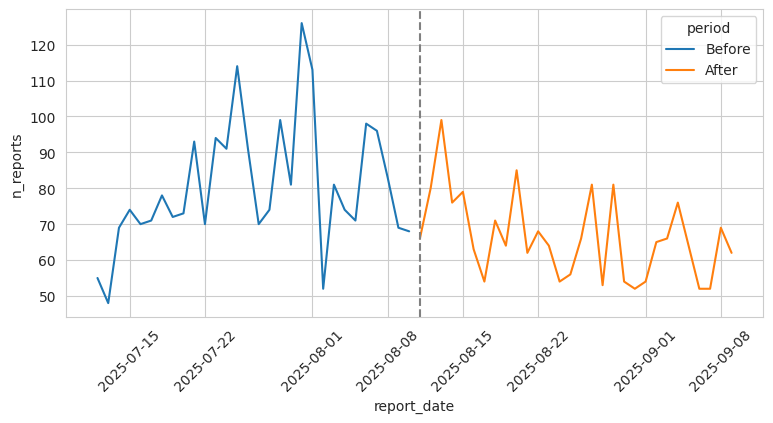

In [9]:
daily_period = df.groupby(by=['report_date', 'period']).size().reset_index(name='n_reports')

sns.lineplot(data=daily_period, x='report_date', y='n_reports', hue='period')
plt.axvline(x=cutoff, color='gray', linestyle='--')
plt.tick_params(axis='x', labelrotation=45)

## Part 4: Count Days from the Cutoff

Subtracting one date from another gives the time between them. Subtract the cutoff from every report date.

In [10]:
gap = df['report_date'] - cutoff

gap.dtype
gap.head(n=3)

dtype('<m8[ns]')

0   -30 days
1   -30 days
2   -30 days
Name: report_date, dtype: timedelta64[ns]

Each value is a length of time. `-30 days` means the report was recorded 30 days before August 11. `.dt.days` keeps the number of days: negative before the cutoff, 0 on August 11, and positive after it.

The last two lines check the new column against `period`. Values of 0 or more should all be After reports, and negative values should all be Before reports.

In [11]:
df['days_from_cutoff'] = (df['report_date'] - cutoff).dt.days
df[['report_date', 'period', 'days_from_cutoff']].head(n=3)

df[df['days_from_cutoff'] >= 0]['period'].unique()
df[df['days_from_cutoff'] < 0]['period'].unique()

,report_date,period,days_from_cutoff
0,2025-07-12,Before,-30
1,2025-07-12,Before,-30
2,2025-07-12,Before,-30


array(['After'], dtype=object)

array(['Before'], dtype=object)

### Plot Against Days from the Cutoff

The horizontal axis is now an ordinary number line, so the cutoff line goes at `x=0`. The axis label names the event date.

<Axes: xlabel='days_from_cutoff', ylabel='n_reports'>

Text(0.5, 0, 'Days from August 11, 2025')

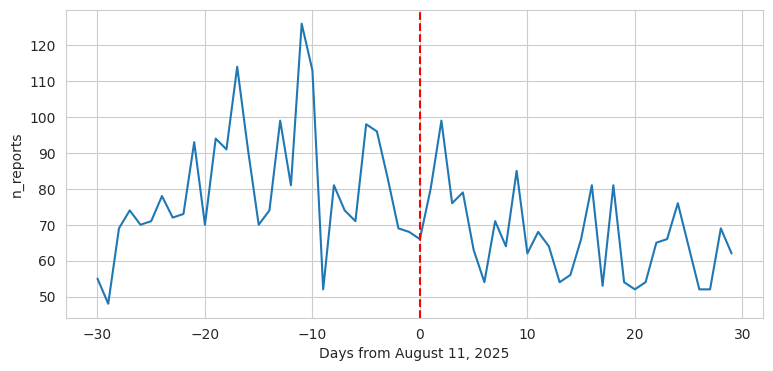

In [12]:
daily_days = df.groupby(by=['days_from_cutoff']).size().reset_index(name='n_reports')

sns.lineplot(data=daily_days, x='days_from_cutoff', y='n_reports')
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel(xlabel='Days from August 11, 2025')

The line matches the date chart. This axis counts days from the event, so the cutoff sits at 0 for any event date, and the axis needs only whole numbers. That makes it a dependable choice when date labels cause trouble. A date axis tells the reader the calendar dates themselves.

## Part 5: Group Days into Weeks

The daily counts rise and fall from one day to the next. Grouping days into weeks smooths the line.

`.dt.to_period(freq='W')` assigns each date to its week. Pandas weeks run Monday through Sunday.

In [13]:
daily['week'] = daily['report_date'].dt.to_period(freq='W')
daily.head(n=3)

,report_date,n_reports,week
0,2025-07-12,55,2025-07-07/2025-07-13
1,2025-07-13,48,2025-07-07/2025-07-13
2,2025-07-14,69,2025-07-14/2025-07-20


Each label shows the first and last day of a week: July 12 and 13 belong to the week of July 7–13. Add up the daily counts in each week, then try to plot the weekly totals.

In [14]:
weekly_period = daily.groupby(by=['week'])['n_reports'].sum().reset_index(name='n_reports')
weekly_period.head(n=3)

,week,n_reports
0,2025-07-07/2025-07-13,103
1,2025-07-14/2025-07-20,507
2,2025-07-21/2025-07-27,623


In [ ]:
# Expected TypeError: plot the week labels
sns.lineplot(data=weekly_period, x='week', y='n_reports')

A week label is a span of seven days, and Seaborn places single dates on a timeline. `.dt.to_timestamp()` turns each week into the date it starts: its Monday.

In [16]:
daily['week_start'] = daily['report_date'].dt.to_period(freq='W').dt.to_timestamp()
daily.head(n=3)

weekly = daily.groupby(by=['week_start'])['n_reports'].sum().reset_index(name='n_reports')
weekly

,report_date,n_reports,week,week_start
0,2025-07-12,55,2025-07-07/2025-07-13,2025-07-07
1,2025-07-13,48,2025-07-07/2025-07-13,2025-07-07
2,2025-07-14,69,2025-07-14/2025-07-20,2025-07-14


,week_start,n_reports
0,2025-07-07,103
1,2025-07-14,507
2,2025-07-21,623
3,2025-07-28,626
4,2025-08-04,559
5,2025-08-11,517
6,2025-08-18,468
7,2025-08-25,443
8,2025-09-01,429
9,2025-09-08,131


<Axes: xlabel='week_start', ylabel='n_reports'>

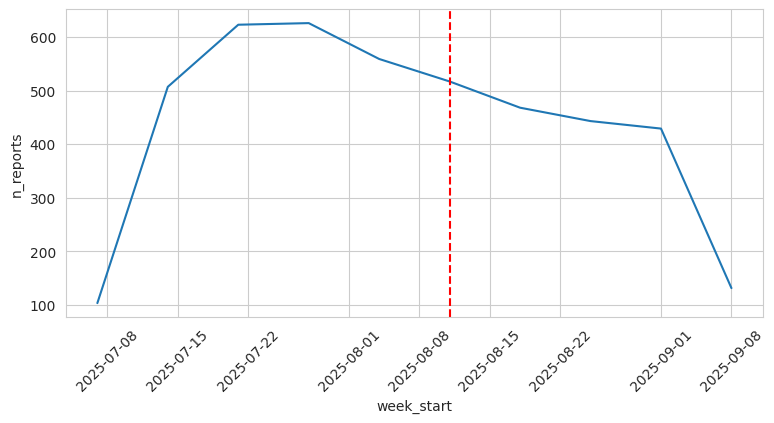

In [17]:
sns.lineplot(data=weekly, x='week_start', y='n_reports')
plt.axvline(x=cutoff, color='red', linestyle='--')
plt.tick_params(axis='x', labelrotation=45)

### Read the First and Last Weeks

The line drops sharply at both ends. The first week has two days of data (July 12–13), and so does the last week (September 8–9). Their totals hold about two days' worth of reports.

Average the daily counts within each week instead. Each week's value then measures reports per day, whether the week has two days of data or seven. The visualization notebook used the same step for months. The two-day weeks still give noisier averages: the first week's value comes from one Saturday and one Sunday.

,week_start,reports_per_day
0,2025-07-07,51.5
1,2025-07-14,72.4
2,2025-07-21,89.0
3,2025-07-28,89.4
4,2025-08-04,79.9
5,2025-08-11,73.9
6,2025-08-18,66.9
7,2025-08-25,63.3
8,2025-09-01,61.3
9,2025-09-08,65.5


<Axes: xlabel='week_start', ylabel='reports_per_day'>

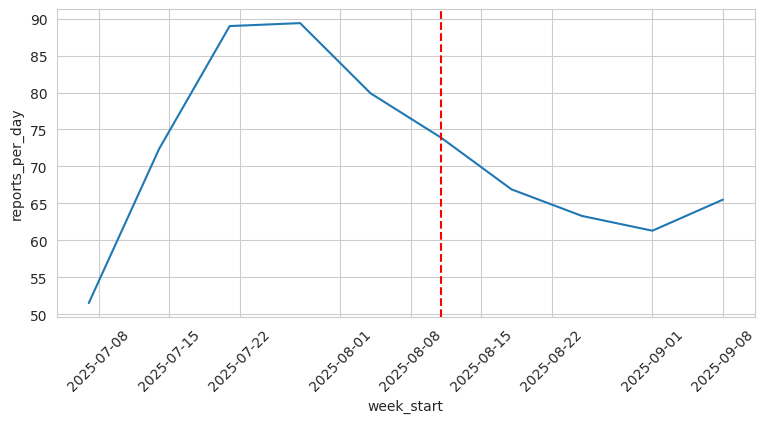

In [18]:
weekly_avg = daily.groupby(by=['week_start'])['n_reports'].mean().round(decimals=1).reset_index(name='reports_per_day')
weekly_avg

sns.lineplot(data=weekly_avg, x='week_start', y='reports_per_day')
plt.axvline(x=cutoff, color='red', linestyle='--')
plt.tick_params(axis='x', labelrotation=45)

Each week's point sits at its Monday. August 11 is a Monday, so the week of August 11 is the point on the cutoff line. Every point to the left of the line is a week of Before days, and every point from the line onward is a week of After days.

## Part 6: Compare Days of the Week

A date part can also serve as a category. `.dt.day_name()` gives each report's weekday. Count the reports for each weekday.

In [19]:
df['weekday'] = df['report_date'].dt.day_name()

weekday_counts = df.groupby(by=['weekday']).size().reset_index(name='n_reports')
weekday_counts

,weekday,n_reports
0,Friday,680
1,Monday,626
2,Saturday,572
3,Sunday,552
4,Thursday,651
5,Tuesday,651
6,Wednesday,674


The grouped table lists the weekdays alphabetically. `order=` sets the order of the bars.

<Axes: xlabel='weekday', ylabel='n_reports'>

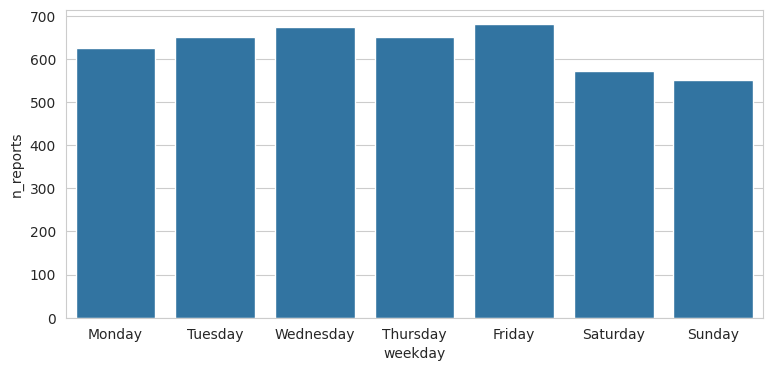

In [20]:
week_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

sns.barplot(data=weekday_counts, x='weekday', y='n_reports', order=week_order)

Each bar adds up the reports recorded on one weekday across the 60 days. The window starts on a Saturday and ends on a Tuesday, so Saturday through Tuesday each appear 9 times and Wednesday through Friday each appear 8 times. Friday has the highest total, 680 reports, from 8 days.

## Hands-On Exercises

Each exercise has two parts. Part A repeats an example with a different selection. Part B changes the time axis.

### Exercise 1: Violent Reports on a Timeline

**Part A:** Filter `df` to reports with `is_violent == True`. Count the reports on each date and plot them with the cutoff line.

**Part B:** Count the same violent reports by `days_from_cutoff` and plot them with a line at 0.

**Question:** Do violent reports show a change near August 11? How large is that change compared with the day-to-day ups and downs?

In [ ]:
# Part A: Select violent reports, count them by report_date, and plot with the cutoff line.

In [ ]:
# Part B: Count violent reports by days_from_cutoff and plot with a line at 0.

### Exercise 2: One Offense by Week and by Weekday

**Part A:** Filter `df` to `'THEFT/OTHER'` reports. Count them on each date, add a `week_start` column, and plot the average reports per day in each week with the cutoff line.

**Part B:** Count the same `'THEFT/OTHER'` reports by `weekday` and draw a bar chart with the days in calendar order.

**Question:** Did other-theft reports per day change after August 11? Which weekday has the most other-theft reports, and how many times does that weekday appear in the 60 days?

In [ ]:
# Part A: Select THEFT/OTHER, count by report_date, add week_start, and plot the weekly averages.

In [ ]:
# Part B: Count THEFT/OTHER reports by weekday and draw a bar chart in calendar order.

## Reference: Dates on a Chart

```python
# Convert text dates
df['date'] = pd.to_datetime(arg=df['date'])

# Daily counts on a timeline, with a cutoff line
daily = df.groupby(by=['date']).size().reset_index(name='n_reports')
sns.lineplot(data=daily, x='date', y='n_reports')
plt.axvline(x=pd.to_datetime(arg='2025-08-11'), color='red', linestyle='--')

# Days from a cutoff, with the line at 0
df['days_from_cutoff'] = (df['date'] - pd.to_datetime(arg='2025-08-11')).dt.days

# Week labels that Seaborn can plot: each week's Monday
daily['week_start'] = daily['date'].dt.to_period(freq='W').dt.to_timestamp()

# Average reports per day within each week
weekly_avg = daily.groupby(by=['week_start'])['n_reports'].mean().reset_index(name='reports_per_day')
```

| What you see | Cause | Fix |
|---|---|---|
| Dozens of overlapping date labels | The date column holds text | Convert it with `pd.to_datetime()` |
| `ConversionError` from `plt.axvline()` | The line's position is text on a date axis | Give `x=` a date from `pd.to_datetime()` |
| `TypeError: Invalid object type` from `sns.lineplot()` | The `x` column holds week periods | Add `.dt.to_timestamp()` |
| The first or last week dips | That week has fewer days of data | Plot the average reports per day |